# HW2:  Uniform Convergence and the Limits of Learning
**Mejrissi Yasmine**

# Partie I : Simulating Uniform Convergence

In [95]:
import numpy as np
import matplotlib.pyplot as plt

In [96]:
p=[0.1, 0.3, 0.5]
sizes = [10, 20, 50, 100, 200, 500, 1000, 2000]
n=10000

**Choix des paramètres.** Je prends p = 0,1, 0,3 et 0,5 pour voir l'effet de la vraie erreur sur la variabilité (la variance p(1−p)/m est maximale en 0,5). Les tailles m vont de 10 à 2000 pour couvrir petits et grands échantillons, avec ε = δ = 0,05. Je teste |H| = 5 à 500 comme suggéré dans le sujet, et N = 10, 50, 100 pour la Partie II. J'utilise 10 000 répétitions pour les tâches 1 et 2, et 2000 pour les suivantes, plus longues à calculer.

## 1. Empirical Risk as a Random Variable

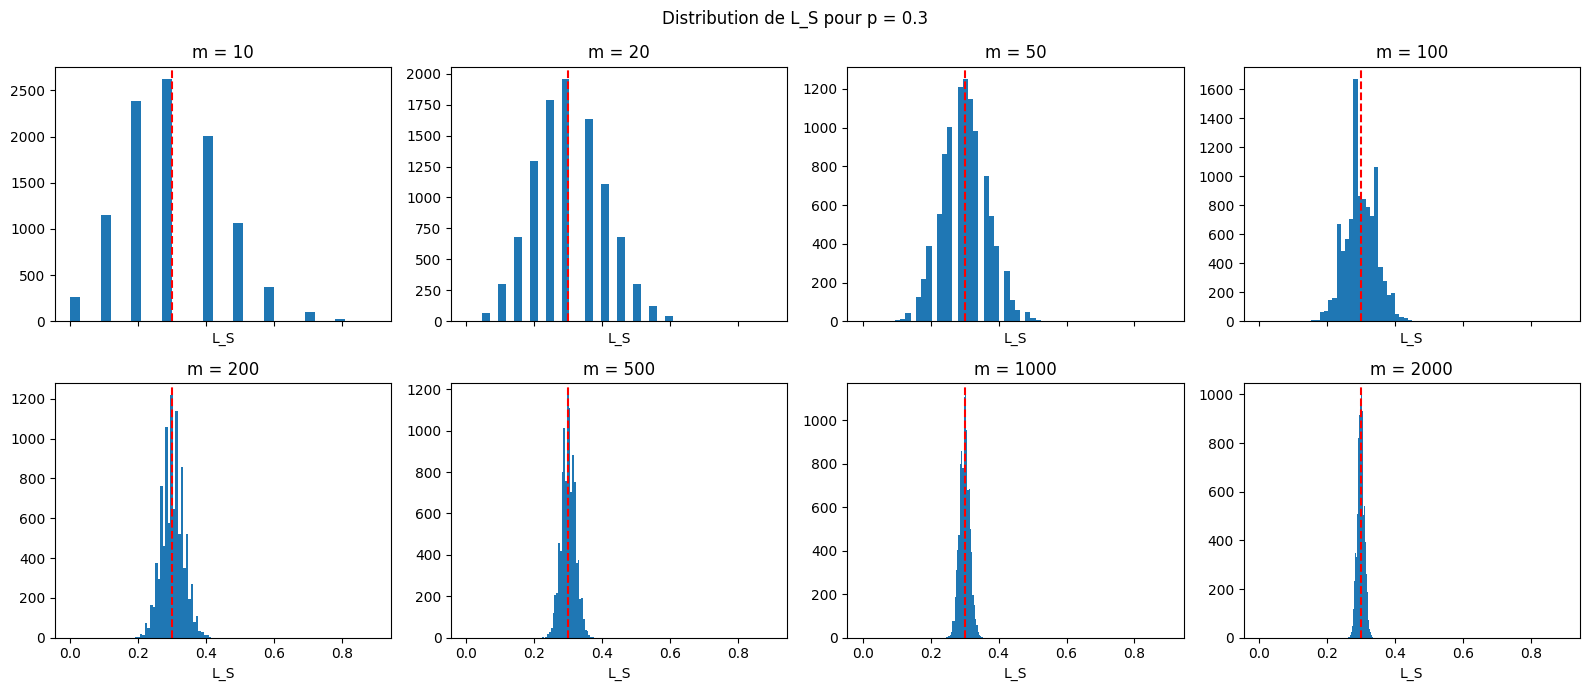

In [97]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flatten()

for i in range(len(sizes)):
    m = sizes[i]
    E = np.random.binomial(m, 0.3, size=10000)
    axes[i].hist(E / m, bins=30, color="tab:blue")
    axes[i].axvline(0.3, color="red", linestyle="--")
    axes[i].set_title(f"m = {m}")
    axes[i].set_xlabel("L_S")

plt.suptitle("Distribution de L_S pour p = 0.3")
plt.tight_layout()
plt.show()

In [98]:
for p in [0.1, 0.3, 0.5]:
    for m in sizes:
        E = np.random.binomial(m, p, size=10000)
        L_S = E / m
        ecart_theorique = np.sqrt(p * (1 - p) / m)
        print(f"p = {p},  m = {m:4d},  moyenne = {L_S.mean():.4f},  écart-type = {L_S.std():.4f},  écart-type théorique = {ecart_theorique:.4f}")

p = 0.1,  m =   10,  moyenne = 0.0992,  écart-type = 0.0942,  écart-type théorique = 0.0949
p = 0.1,  m =   20,  moyenne = 0.1002,  écart-type = 0.0673,  écart-type théorique = 0.0671
p = 0.1,  m =   50,  moyenne = 0.1002,  écart-type = 0.0427,  écart-type théorique = 0.0424
p = 0.1,  m =  100,  moyenne = 0.1000,  écart-type = 0.0301,  écart-type théorique = 0.0300
p = 0.1,  m =  200,  moyenne = 0.0999,  écart-type = 0.0215,  écart-type théorique = 0.0212
p = 0.1,  m =  500,  moyenne = 0.1001,  écart-type = 0.0135,  écart-type théorique = 0.0134
p = 0.1,  m = 1000,  moyenne = 0.0999,  écart-type = 0.0095,  écart-type théorique = 0.0095
p = 0.1,  m = 2000,  moyenne = 0.0999,  écart-type = 0.0067,  écart-type théorique = 0.0067
p = 0.3,  m =   10,  moyenne = 0.2998,  écart-type = 0.1436,  écart-type théorique = 0.1449
p = 0.3,  m =   20,  moyenne = 0.3005,  écart-type = 0.1027,  écart-type théorique = 0.1025
p = 0.3,  m =   50,  moyenne = 0.3010,  écart-type = 0.0652,  écart-type théoriq

La moyenne de L_S est très proche de p pour toutes les valeurs de p et de m : l'erreur empirique est un estimateur sans biais de la vraie erreur.
Cependant la variabilité dépend fortement de m. Son écart-type suit la formule √(p(1−p)/m) et diminue quand m augmente : pour p = 0,3, il passe de 0,065 (m = 50) à 0,032 (m = 200). Avec plus de données, L_S se concentre donc autour de p.

Pour un même m, l'écart-type est plus grand pour p = 0,5 que pour p = 0,1, car p(1−p) est maximal en p = 0,5.
Avec peu de données, L_S peut donc être loin de la vraie erreur ; avec beaucoup de données, elle se concentre autour de p, comme on le voit sur les histogrammes.


## 2. Deviation Between Empirical and True Risk

In [99]:
eps = 0.05
p = 0.3


proba_exp = []
proba_hoeffding = []

for m in sizes:
    E = np.random.binomial(m, p, size=10000)
    L_S = E / m
    ecart = np.abs(L_S - p)
    proba_exp.append((ecart > eps).mean())
    proba_hoeffding.append(2 * np.exp(-2 * m * eps**2))

for i in range(len(sizes)):
    print(f"m = {sizes[i]:4d},  proba expérimentale = {proba_exp[i]:.4f}, borne de Hoeffding = {proba_hoeffding[i]:.4f}")

m =   10,  proba expérimentale = 0.7361, borne de Hoeffding = 1.9025
m =   20,  proba expérimentale = 0.4595, borne de Hoeffding = 1.8097
m =   50,  proba expérimentale = 0.4369, borne de Hoeffding = 1.5576
m =  100,  proba expérimentale = 0.2309, borne de Hoeffding = 1.2131
m =  200,  proba expérimentale = 0.1035, borne de Hoeffding = 0.7358
m =  500,  proba expérimentale = 0.0143, borne de Hoeffding = 0.1642
m = 1000,  proba expérimentale = 0.0005, borne de Hoeffding = 0.0135
m = 2000,  proba expérimentale = 0.0000, borne de Hoeffding = 0.0001


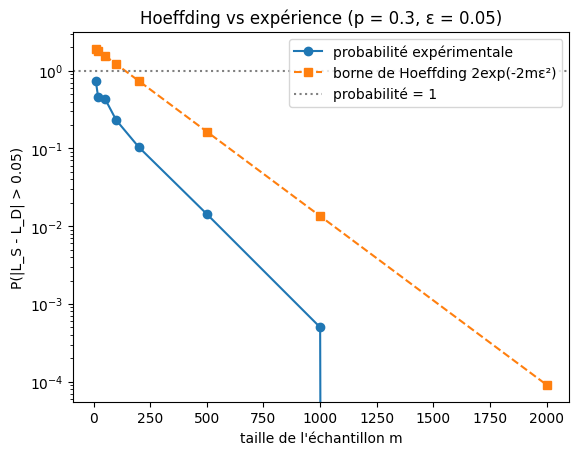

In [100]:
plt.plot(sizes, proba_exp, "o-", label="probabilité expérimentale")
plt.plot(sizes, proba_hoeffding, "s--", label="borne de Hoeffding 2exp(-2mε²)")
plt.axhline(1, color="gray", linestyle=":", label="probabilité = 1")
plt.yscale("log")
plt.xlabel("taille de l'échantillon m")
plt.ylabel(f"P(|L_S - L_D| > {eps})")
plt.title(f"Hoeffding vs expérience (p = {p}, ε = {eps})")
plt.legend()
plt.show()

La probabilité que l'erreur empirique s'écarte de la vraie erreur de plus de ε diminue rapidement quand m augmente : elle vaut environ 0,74 pour m = 10 et 0,0005 pour m = 1000.
La borne de Hoeffding est toujours au-dessus de la probabilité expérimentale, elle est donc bien vérifiée. Mais elle n'est pas exacte : elle est conservatrice. Pour m ≤ 100, elle dépasse 1. Pour m = 1000, elle vaut 0,0135, soit environ 30 fois la probabilité observée.
Cela s'explique par le fait que l'inégalité de Hoeffding est valable pour toute variable bornée, quelle que soit sa loi : c'est une garantie mais pas une estimation précise.

## 3. From One Hypothesis to Uniform Convergence

In [101]:
p=[0.1, 0.3, 0.5]
m=20
err=np.random.binomial(m, p)
L_S=err/m
ecarts=np.abs(L_S-p)
delta=np.max(ecarts)

print("Nombre d'erreurs de chaque hypothèse: ", err)
print("erreurs empiriques: ", L_S)
print("écart de chaque hypothèse: ", ecarts)
print("échec: ", delta>0.05)

Nombre d'erreurs de chaque hypothèse:  [ 1  7 11]
erreurs empiriques:  [0.05 0.35 0.55]
écart de chaque hypothèse:  [0.05 0.05 0.05]
échec:  True


In [102]:
K=50
p_val=np.random.uniform(0, 0.5, size=K)
eps=0.05
n=2000
sizes=[10, 20 ,50, 100, 200, 500, 1000, 2000]

proba=[]
borne=[]

for m in sizes:
  nb_echecs=0
  for r in range(n):
    E=np.random.binomial(m, p_val)
    L_S=E/m
    delta=np.max(np.abs(L_S-p_val))
    if delta>eps:
      nb_echecs+=1
  proba.append(nb_echecs/n)
  borne.append(2*K*np.exp(-2*m*eps**2))

for i in range(len(sizes)):
  print(f"m={sizes[i]:4d}, Pr(∆_S>ε) = {proba[i]:4f}, borne = {borne[i]:4f}")

m=  10, Pr(∆_S>ε) = 1.000000, borne = 95.122942
m=  20, Pr(∆_S>ε) = 1.000000, borne = 90.483742
m=  50, Pr(∆_S>ε) = 1.000000, borne = 77.880078
m= 100, Pr(∆_S>ε) = 1.000000, borne = 60.653066
m= 200, Pr(∆_S>ε) = 0.992500, borne = 36.787944
m= 500, Pr(∆_S>ε) = 0.388500, borne = 8.208500
m=1000, Pr(∆_S>ε) = 0.025000, borne = 0.673795
m=2000, Pr(∆_S>ε) = 0.000000, borne = 0.004540


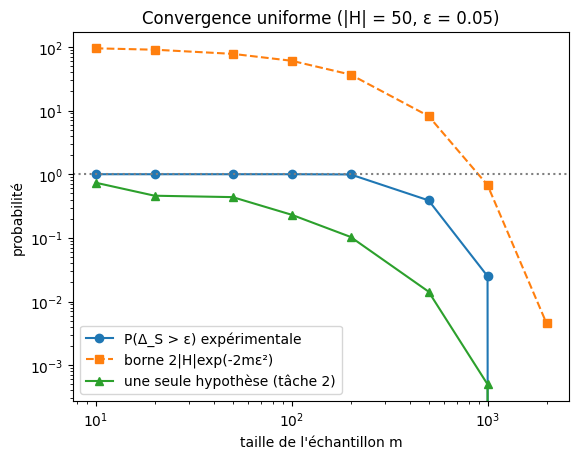

In [103]:
plt.plot(sizes, proba, "o-", label="P(Δ_S > ε) expérimentale")
plt.plot(sizes, borne, "s--", label="borne 2|H|exp(-2mε²)")
plt.plot(sizes, proba_exp, "^-", label="une seule hypothèse (tâche 2)")
plt.axhline(1, color="gray", linestyle=":")
plt.yscale("log")
plt.xscale("log")
plt.xlabel("taille de l'échantillon m")
plt.ylabel("probabilité")
plt.title(f"Convergence uniforme (|H| = {K}, ε = {eps})")
plt.legend()
plt.show()

Avec 50 hypothèses, la probabilité que le pire écart Δ_S dépasse ε est beaucoup plus grande qu'avec une seule hypothèse : pour m = 200, elle vaut presque 1, contre environ 0,11 pour une hypothèse seule.
Il suffirait qu'une hypothèse ait une erreur empirique éloignée de sa vraie erreur pour que l'échantillon soit un échec. La convergence uniforme demande beaucoup plus de données. La probabilité ne devient faible qu'à partir de m ≈ 1000.
La borne 2|H|exp(−2mε²) est vérifiée, mais reste conservatrice : elle dépasse 1 jusqu'à m = 500.


## 4. Effect of the Size of the Hypothesis Class

In [104]:
K_nv=[5, 10, 50, 100, 500]
resultats={}
for k in K_nv:
  p=np.random.uniform(0, 0.5, size=k)
  proba_K=[]
  for m in sizes:
    nb_echecs=0
    for r in range(n):
      E=np.random.binomial(m, p)
      L_S=E/m
      delta=np.max(np.abs(L_S-p))
      if delta>eps:
        nb_echecs+=1
    proba_K.append(nb_echecs/n)
  resultats[k]=proba_K
  print(f"|H|= {k} : ", proba_K)

|H|= 5 :  [0.9845, 0.939, 0.772, 0.4855, 0.2025, 0.025, 0.001, 0.0]
|H|= 10 :  [1.0, 0.999, 0.986, 0.9, 0.567, 0.0865, 0.002, 0.0]
|H|= 50 :  [1.0, 1.0, 1.0, 1.0, 0.991, 0.371, 0.0275, 0.0]
|H|= 100 :  [1.0, 1.0, 1.0, 1.0, 1.0, 0.6335, 0.0345, 0.0]
|H|= 500 :  [1.0, 1.0, 1.0, 1.0, 1.0, 0.9965, 0.249, 0.0015]


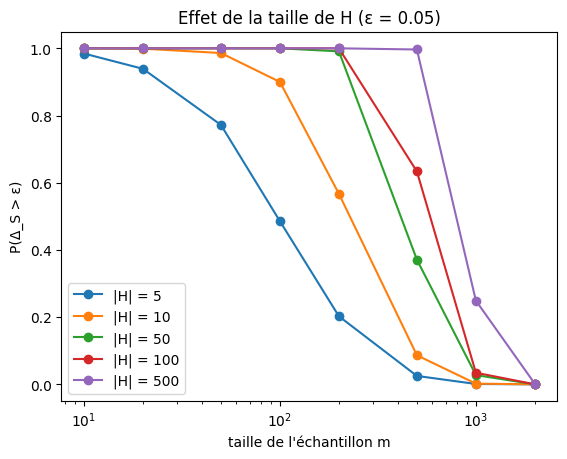

In [105]:
for k in K_nv:
    plt.plot(sizes, resultats[k], "o-", label=f"|H| = {k}")
plt.xscale("log")
plt.xlabel("taille de l'échantillon m")
plt.ylabel("P(Δ_S > ε)")
plt.title(f"Effet de la taille de H (ε = {eps})")
plt.legend()
plt.show()

Plus |H| est grand, plus il faut de données : à m = 500, P(Δ_S > ε) vaut environ 0,025 pour |H| = 5, mais presque 1 pour |H| = 500.
Plus il y a d'hypothèses, plus il est probable qu'au moins l'une d'elles ait une erreur empirique loin de sa vraie erreur.
Une classe plus grande demande donc plus de données.
L'augmentation reste lente : 100 fois plus d'hypothèses ne demandent que 2 à 4 fois plus d'exemples, ce qui correspond à la dépendance en log|H| des bornes théoriques.

## 5. Experimental Sample Complexity

In [106]:
delta=0.05
m_exp_liste=[]
for k in K_nv:
  m_exp=None
  for i in range(len(sizes)):
    if resultats[k][i]<=delta:
      m_exp=sizes[i]
      break
  m_exp_liste.append(m_exp)
  m_theorique=np.round(np.log(2*k/delta)/(2*eps**2), 4)
  print(f"|H|={k}, m expérimental={m_exp}, m théorique = {m_theorique}")

|H|=5, m expérimental=500, m théorique = 1059.6635
|H|=10, m expérimental=1000, m théorique = 1198.2929
|H|=50, m expérimental=1000, m théorique = 1520.1805
|H|=100, m expérimental=1000, m théorique = 1658.8099
|H|=500, m expérimental=2000, m théorique = 1980.6975


Avec ε = 0,05 et δ = 0,05, la taille d'échantillon trouvée expérimentalement est généralement plus petite que la taille théorique : par exemple, pour |H| = 50, 1000 exemples suffisent en pratique, alors que la formule en demande environ 1520.
Pour |H| = 500, le m expérimental qui est égal à 2000 semble un peu au-dessus du m théorique qui est égal à 1981, mais c'est dû aux valeurs de m que j'ai testées : il n'y a pas d'entre-deux entre 1000 et 2000, donc le vrai minimum devrait se situer dans cet intervalle.

La borne théorique est une garantie suffisante, mais ce n'est pas une taille minimale exacte. Elle combine l'inégalité de Hoeffding et la borne d'union. Les vraies probabilités sont plus petites, et moins d'exemples suffisent.
La formule garantit bien le résultat dans tous les cas, et elle reproduit bien la croissance lente, en log|H|, vue dans la tâche 4.

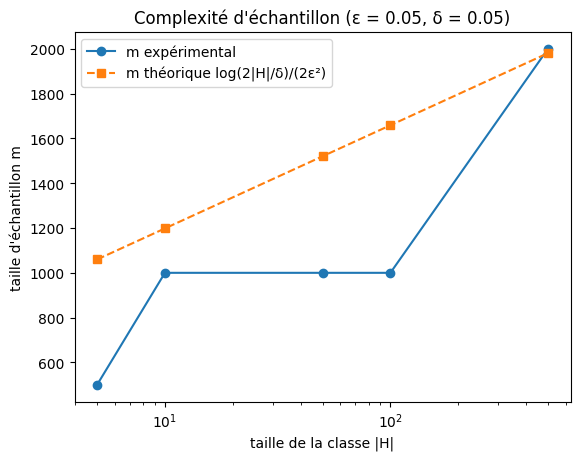

In [115]:
m_theorique_liste = [np.log(2 * k / delta) / (2 * eps**2) for k in K_nv]

plt.plot(K_nv, m_exp_liste, "o-", label="m expérimental")
plt.plot(K_nv, m_theorique_liste, "s--", label="m théorique log(2|H|/δ)/(2ε²)")
plt.xscale("log")
plt.xlabel("taille de la classe |H|")
plt.ylabel("taille d'échantillon m")
plt.title(f"Complexité d'échantillon (ε = {eps}, δ = {delta})")
plt.legend()
plt.show()

La courbe expérimentale est en escalier car le m expérimental ne peut prendre que les valeurs testées (500, 1000 ou 2000).

# Partie II : Simulating No-Free-Lunch

## 6. Seen and Unseen Inputs

In [108]:
N_valeurs=[10, 50, 100]
sizes_nfl=[5, 10, 20, 50, 100, 200, 500]
n=2000

for N in N_valeurs:
  for m in sizes_nfl:
    fractions_non_vus=[]
    for r in range(n):
      f=np.random.randint(0, 2, size=N)
      echantillon=np.random.randint(1, N+1, size=m)
      seen=np.unique(echantillon)
      fractions_non_vus.append(1-len(seen)/N)
    fraction_theorique=(1-1/N)**m
    print(f"N = {N},m={m}, fraction non vue={np.mean(fractions_non_vus):.4f}, (1-1/N)^m={fraction_theorique:.4f}")

N = 10,m=5, fraction non vue=0.5917, (1-1/N)^m=0.5905
N = 10,m=10, fraction non vue=0.3490, (1-1/N)^m=0.3487
N = 10,m=20, fraction non vue=0.1235, (1-1/N)^m=0.1216
N = 10,m=50, fraction non vue=0.0051, (1-1/N)^m=0.0052
N = 10,m=100, fraction non vue=0.0000, (1-1/N)^m=0.0000
N = 10,m=200, fraction non vue=0.0000, (1-1/N)^m=0.0000
N = 10,m=500, fraction non vue=0.0000, (1-1/N)^m=0.0000
N = 50,m=5, fraction non vue=0.9041, (1-1/N)^m=0.9039
N = 50,m=10, fraction non vue=0.8172, (1-1/N)^m=0.8171
N = 50,m=20, fraction non vue=0.6675, (1-1/N)^m=0.6676
N = 50,m=50, fraction non vue=0.3636, (1-1/N)^m=0.3642
N = 50,m=100, fraction non vue=0.1330, (1-1/N)^m=0.1326
N = 50,m=200, fraction non vue=0.0174, (1-1/N)^m=0.0176
N = 50,m=500, fraction non vue=0.0000, (1-1/N)^m=0.0000
N = 100,m=5, fraction non vue=0.9509, (1-1/N)^m=0.9510
N = 100,m=10, fraction non vue=0.9044, (1-1/N)^m=0.9044
N = 100,m=20, fraction non vue=0.8177, (1-1/N)^m=0.8179
N = 100,m=50, fraction non vue=0.6052, (1-1/N)^m=0.6050
N =

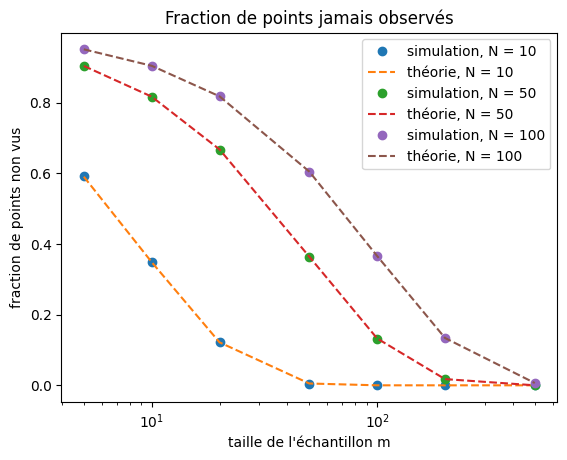

In [109]:
for N in N_valeurs:
    fraction_simulee = []
    fraction_theorique = []
    for m in sizes_nfl:
        fractions_non_vus = []
        for r in range(n):
            echantillon = np.random.randint(1, N + 1, size=m)
            seen = np.unique(echantillon)
            fractions_non_vus.append(1 - len(seen) / N)
        fraction_simulee.append(np.mean(fractions_non_vus))
        fraction_theorique.append((1 - 1 / N) ** m)
    plt.plot(sizes_nfl, fraction_simulee, "o", label=f"simulation, N = {N}")
    plt.plot(sizes_nfl, fraction_theorique, "--", label=f"théorie, N = {N}")

plt.xscale("log")
plt.xlabel("taille de l'échantillon m")
plt.ylabel("fraction de points non vus")
plt.title("Fraction de points jamais observés")
plt.legend()
plt.show()

La fraction de points jamais observés correspond à la formule (1 − 1/N)^m, pour tous les N et tous les m testés.
C'est également la fraction attendue de points non vus : la fraction non vue est la moyenne, sur les N points, de l'indicatrice « x n'est pas vu ». Par linéarité de l'espérance, son espérance est la moyenne des probabilités, qui valent toutes (1 − 1/N)^m.
Cette fraction diminue quand m augmente, mais lentement : Même avec m = N tirages, environ 37 % des points restent non vus, car (1 − 1/N)^N tend vers 1/e.


## 7. Error on Unseen Inputs

N = 10, m = 5, erreur simulée = 0.2958, théorique = 0.2952
N = 10, m = 10, erreur simulée = 0.1774, théorique = 0.1743
N = 10, m = 20, erreur simulée = 0.0611, théorique = 0.0608
N = 10, m = 50, erreur simulée = 0.0020, théorique = 0.0026
N = 10, m = 100, erreur simulée = 0.0000, théorique = 0.0000
N = 10, m = 200, erreur simulée = 0.0000, théorique = 0.0000
N = 10, m = 500, erreur simulée = 0.0000, théorique = 0.0000
N = 50, m = 5, erreur simulée = 0.4506, théorique = 0.4520
N = 50, m = 10, erreur simulée = 0.4076, théorique = 0.4085
N = 50, m = 20, erreur simulée = 0.3330, théorique = 0.3338
N = 50, m = 50, erreur simulée = 0.1809, théorique = 0.1821
N = 50, m = 100, erreur simulée = 0.0667, théorique = 0.0663
N = 50, m = 200, erreur simulée = 0.0088, théorique = 0.0088
N = 50, m = 500, erreur simulée = 0.0000, théorique = 0.0000
N = 100, m = 5, erreur simulée = 0.4757, théorique = 0.4755
N = 100, m = 10, erreur simulée = 0.4516, théorique = 0.4522
N = 100, m = 20, erreur simulée = 0

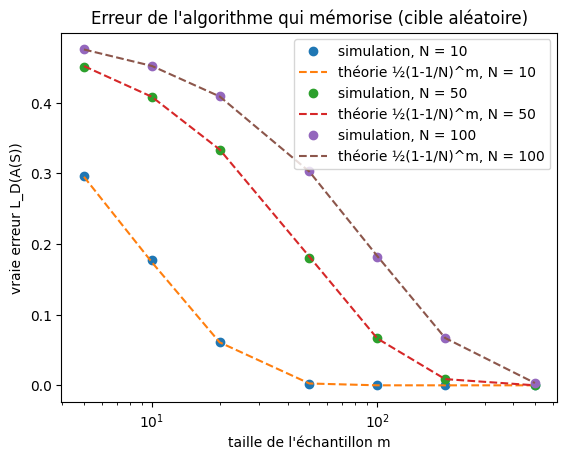

In [110]:
for N in N_valeurs:
  erreur_simulee=[]
  erreur_theorique=[]
  for m in sizes_nfl:
    erreurs=[]
    for r in range(n):
      f=np.random.randint(0, 2, size=N)
      echantillon=np.random.randint(0, N, size=m)
      prediction=np.zeros(N)
      prediction[echantillon]=f[echantillon]
      erreurs.append(np.mean(prediction != f))
    erreur_simulee.append(np.mean(erreurs))
    erreur_theorique.append(0.5*(1-1/N)**m)
    print(f"N = {N}, m = {m}, erreur simulée = {erreur_simulee[-1]:.4f}, théorique = {erreur_theorique[-1]:.4f}")
  plt.plot(sizes_nfl, erreur_simulee, "o", label=f"simulation, N = {N}")
  plt.plot(sizes_nfl, erreur_theorique, "--", label=f"théorie ½(1-1/N)^m, N = {N}")

plt.xscale("log")
plt.xlabel("taille de l'échantillon m")
plt.ylabel("vraie erreur L_D(A(S))")
plt.title("Erreur de l'algorithme qui mémorise (cible aléatoire)")
plt.legend()
plt.show()

L'erreur simulée correspond à ½ (1 − 1/N)^m. Toutes les erreurs viennent des points non vus, où l'algorithme se trompe une fois sur deux car les étiquettes sont indépendantes.
L'erreur diminue seulement parce qu'il reste moins de points non vus, pas parce que l'algorithme apprend une règle.

## 8. Changing the Prediction on Unseen Inputs

0 : [0.4522 0.4098 0.3332 0.1827 0.0659 0.0087 0.    ]
1 : [0.455  0.4068 0.3359 0.1819 0.0656 0.0094 0.    ]
random : [0.4513 0.4083 0.3359 0.1806 0.0656 0.0089 0.    ]


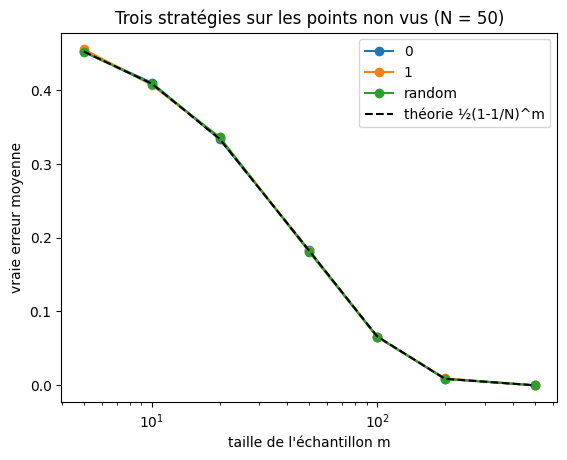

In [111]:
N = 50
s = ["0", "1", "random"]

for i in s:
    erreur_simulee = []
    for m in sizes_nfl:
        erreurs = []
        for r in range(n):
            f = np.random.randint(0, 2, size=N)
            echantillon = np.random.randint(0, N, size=m)
            if i == "0":
                prediction = np.zeros(N)
            elif i == "1":
                prediction = np.ones(N)
            else:
                prediction = np.random.randint(0, 2, size=N)

            prediction[echantillon] = f[echantillon]
            erreurs.append(np.mean(prediction != f))
        erreur_simulee.append(np.mean(erreurs))
    print(i, ":", np.round(erreur_simulee, 4))
    plt.plot(sizes_nfl, erreur_simulee, "o-", label=i)

erreur_theorique = [0.5 * (1 - 1 / N) ** m for m in sizes_nfl]
plt.plot(sizes_nfl, erreur_theorique, "k--", label="théorie ½(1-1/N)^m")
plt.xscale("log")
plt.xlabel("taille de l'échantillon m")
plt.ylabel("vraie erreur moyenne")
plt.title(f"Trois stratégies sur les points non vus (N = {N})")
plt.legend()
plt.show()

Les trois stratégies donnent exactement la même erreur pour tous les m, qui est égal à  ½ (1 − 1/N)^m. Aucune stratégie ne fait mieux que les autres.
Quand la cible est tirée complètement au hasard, l'étiquette d'un point non vu vaut 0 ou 1 avec probabilité 1/2, indépendamment de tout ce qu'on a observé. Que l'on prédise 0, 1 ou une valeur au hasard, on a toujours une chance sur deux de se tromper sur ce point.

C'est le No-Free-Lunch :  sans hypothèse sur la cible, l'échantillon ne dit rien des points non observés. Pour généraliser, il faut faire une hypothèse sur la forme de la cible, c'est-à-dire introduire un biais inductif.

# Partie III : Introducing Prior Knowledge

## 9. Learning with a Matching Inductive Bias

In [112]:
N = 50
x = np.arange(1, N + 1)
seuils = np.arange(1, N)

erreur_seuil = []
erreur_nfl = []

for m in sizes_nfl:
    erreurs = []
    for r in range(n):
        theta = np.random.randint(1, N)                      # (a) seuil cible au hasard
        f = (x > theta).astype(int)                  # étiquettes de tous les points
        x_train = np.random.randint(1, N + 1, size=m)        # (b) échantillon
        y_train = (x_train > theta).astype(int)
        risques = [np.mean((x_train > t).astype(int) != y_train) for t in seuils]
        t_appris = seuils[np.argmin(risques)]
        prediction = (x > t_appris).astype(int)
        erreurs.append(np.mean(prediction != f))
    erreur_seuil.append(np.mean(erreurs))
    erreur_nfl.append(0.5 * (1 - 1 / N) ** m)               # formule de la tâche 7
    print(f"m = {m:3d} | erreur ERM seuils = {erreur_seuil[-1]:.4f} | erreur mémorisation (cible aléatoire) = {erreur_nfl[-1]:.4f}")

m =   5 | erreur ERM seuils = 0.1322 | erreur mémorisation (cible aléatoire) = 0.4520
m =  10 | erreur ERM seuils = 0.0724 | erreur mémorisation (cible aléatoire) = 0.4085
m =  20 | erreur ERM seuils = 0.0365 | erreur mémorisation (cible aléatoire) = 0.3338
m =  50 | erreur ERM seuils = 0.0113 | erreur mémorisation (cible aléatoire) = 0.1821
m = 100 | erreur ERM seuils = 0.0030 | erreur mémorisation (cible aléatoire) = 0.0663
m = 200 | erreur ERM seuils = 0.0003 | erreur mémorisation (cible aléatoire) = 0.0088
m = 500 | erreur ERM seuils = 0.0000 | erreur mémorisation (cible aléatoire) = 0.0000


Avec une cible à seuil et un ERM sur la classe des seuils, la vraie erreur moyenne est beaucoup plus faible que dans la Partie II : environ 0,07 pour m = 10, contre 0,41 pour l'algorithme qui mémorise sur une cible aléatoire, et environ 0,01 pour m = 50, contre 0,18.
Dès m = 100, l'erreur est presque nulle (environ 0,003), alors qu'avec 100 tirages sur 50 points, il reste encore en moyenne 13 % de points jamais vus.
Donc l'algorithme se trompe très peu, même sur des points qu'il n'a jamais observés : le seuil appris à partir de quelques exemples permet de prédire correctement tout le reste du domaine. Il n'y a que les points qui sont situés entre le seuil appris et le vrai seuil θ qui peuvent être mal classés, et cet intervalle se réduit rapidement quand m augmente.

## 10. Random Targets vs. Structured Targets

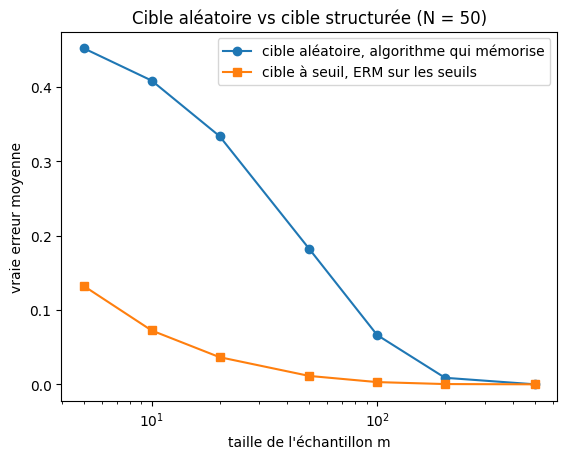

In [113]:
plt.plot(sizes_nfl, erreur_nfl, "o-", label="cible aléatoire, algorithme qui mémorise")
plt.plot(sizes_nfl, erreur_seuil, "s-", label="cible à seuil, ERM sur les seuils")
plt.xscale("log")
plt.xlabel("taille de l'échantillon m")
plt.ylabel("vraie erreur moyenne")
plt.title(f"Cible aléatoire vs cible structurée (N = {N})")
plt.legend()
plt.show()

Avec une cible aléatoire, l'erreur reste élevée tant que beaucoup de points ne sont pas vus. Avec une cible à seuil, elle est faible dès les premiers exemples : 0,07 contre 0,41 pour m = 10.
Si la cible est un seuil, les étiquettes sont liées entre elles : un point étiqueté 1 implique que tous les points plus grands le sont aussi. Quelques exemples suffisent donc pour situer le seuil et prédire les points non vus. Ce biais inductif permet de généraliser, à condition qu'il corresponde à la vraie cible.

## 11. Final Analysis

Dans la Partie I, nous avons vu que l'erreur empirique L_S(h) se rapproche de la vraie erreur L_D(h) quand on a plus de données. En moyenne, elle tombe toujours juste, et ses fluctuations diminuent en 1/√m, puisque c'est une moyenne de m erreurs indépendantes.
Mais l'ERM ne regarde pas une seule hypothèse : il choisit parmi toute la classe H. Pour que son choix soit fiable, il faut que toutes les hypothèses soient bien estimées en même temps. C'est la convergence uniforme : une seule hypothèse mal estimée suffit à fausser le résultat.
Plus la classe est grande, plus ce risque augmente, et plus il faut de données. Nous avons également pu constater que l'augmentation reste lente : elle suit log|H|, comme le prévoient les bornes que nous avons vues en cours (bornes PAC Agnostique).
Les bornes reposent sur le fait que Hoeffding fonctionne pour n'importe quelle loi, et sur la borne d'union, qui additionne les risques d'échec de toutes les hypothèses. Le point négatif est qu'elles demandent beaucoup plus d'exemples que nécessaire en pratique.

Dans la Partie II, la cible était tirée complètement au hasard. Sur un point jamais vu, l'algorithme n'a aucun moyen de deviner l'étiquette : qu'il prédise 0, 1 ou au hasard, il se trompe une fois sur deux. C'est le No-Free-Lunch : sans hypothèse sur la cible, l'échantillon ne dit rien sur les points qu'on n'a pas observés, et l'algorithme ne peut que mémoriser ce qu'il a vu.

Dans la Partie III, nous avons supposé que la cible était un seuil, et nous avons limité la classe d'hypothèses aux seuils. C'est une connaissance a priori, un biais inductif : on écarte d'emblée toutes les cibles qui ne sont pas des seuils. Comme cette hypothèse était juste, quelques exemples ont suffi pour retrouver le seuil, et l'algorithme a bien prédit des points qu'il n'avait jamais vus.

On peut conclure que pour qu'un modèle apprenne bien, il faut qu'il y ait suffisamment de données pour que l'erreur empirique soit fiable sur toute la classe, et une classe d'hypothèses adaptée au problème, qui apporte ce que les données seules ne peuvent pas apprendre.